In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm
from scipy.stats import zscore


In [2]:
workdir = Path("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_skull_workdir/")

In [3]:
scallings = []
index = []
for fold in tqdm(list(workdir.iterdir())):
    scaller_mat = np.loadtxt(fold/"scalling_head.mat")
    scallings.append( [scaller_mat[0,0],scaller_mat[1,1],scaller_mat[2,2]]  )
    index.append(fold.name)



  0%|          | 0/778 [00:00<?, ?it/s]

array([[<AxesSubplot:title={'center':'0'}>,
        <AxesSubplot:title={'center':'1'}>],
       [<AxesSubplot:title={'center':'2'}>, <AxesSubplot:>]], dtype=object)

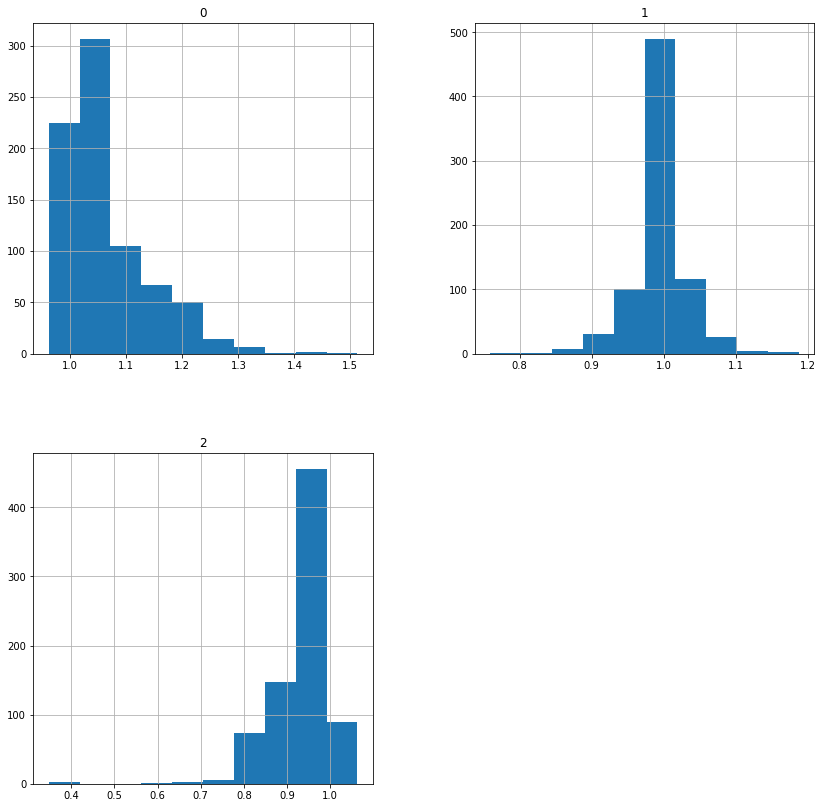

In [4]:
df_scal = pd.DataFrame(scallings,index=index)
df_scal.hist(figsize=(14,14))

In [5]:
males = []
females = []
for fold in tqdm(list(workdir.iterdir())):

    scaller_mat = np.loadtxt(fold/"scalling_head.mat")
    if "F" == fold.name.split("_")[1]:

        males.append( [scaller_mat[0,0],scaller_mat[1,1],scaller_mat[2,2]]  )
    elif "M" == fold.name.split("_")[1]:
        females.append( [scaller_mat[0,0],scaller_mat[1,1],scaller_mat[2,2]]  )
    else:
        print("ERRROR " + fold.name)

pd_males = pd.DataFrame(males)
pd_females = pd.DataFrame(females)


  0%|          | 0/778 [00:00<?, ?it/s]

<AxesSubplot:>

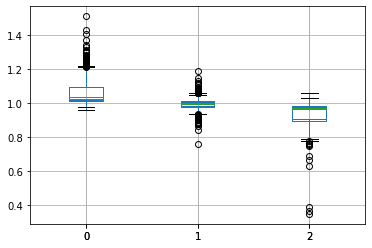

In [6]:
pd_males.boxplot()
pd_females.boxplot()

In [7]:
pd_males.describe()

,0,1,2
count,355.000000,355.000000,355.000000
mean,1.061885,0.993680,0.932886
std,0.079021,0.036772,0.074756
min,0.961428,0.866866,0.347534
25%,1.011170,0.980519,0.896297
50%,1.026810,0.997472,0.963532
75%,1.095617,1.010060,0.979847
max,1.512588,1.187812,1.063121


In [8]:
pd_females.describe()

,0,1,2
count,423.000000,423.000000,423.000000
mean,1.064482,0.996907,0.943069
std,0.070217,0.035839,0.065313
min,0.977109,0.758998,0.362098
25%,1.017281,0.983515,0.905729
50%,1.036175,1.000362,0.970513
75%,1.095967,1.013900,0.985308
max,1.370363,1.121983,1.033149


<AxesSubplot:>

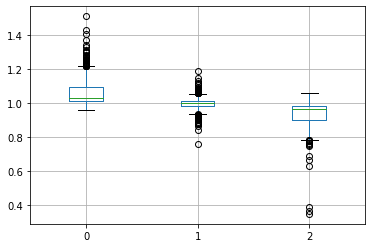

In [9]:
df_scal.boxplot()

In [10]:
df_scal.describe()

,0,1,2
count,778.000000,778.000000,778.000000
mean,1.063297,0.995435,0.938422
std,0.074326,0.036280,0.069919
min,0.961428,0.758998,0.347534
25%,1.014586,0.981896,0.902210
50%,1.031681,0.998506,0.968015
75%,1.095985,1.012095,0.982914
max,1.512588,1.187812,1.063121


In [11]:
df_scal[df_scal[0]>1.3]

,0,1,2
wt_F_82Z-10143,1.306014,1.111448,0.969905
wt_M_82Z-CF807,1.302755,0.758998,0.666353
wt_M_82Z-CE722,1.329617,0.876641,0.362098
wt_M_82Z-07240,1.300694,1.015320,0.892289
wt_F_82Z-07248,1.407213,1.148710,1.063121
wt_M_82Z-07340,1.370363,1.092052,0.997551
wt_F_82Z-07243,1.512588,1.187812,0.963257
wt_F_82Z-07342,1.343409,0.906456,0.347534
wt_F_82Z-11933,1.312250,0.966174,0.910258
wt_F_82Z-02979,1.430007,0.878044,0.831080


In [12]:
df_scal[df_scal[2]<0.8]

,0,1,2
wt_F_82Z-CG968,1.116138,0.987095,0.780272
wt_F_82Z-08087,1.095061,1.006226,0.780317
wt_F_82Z-07465,1.085861,0.980512,0.796538
wt_M_82Z-10327,1.055434,0.907881,0.789358
wt_M_82Z-CF807,1.302755,0.758998,0.666353
wt_M_82Z-CG058,1.147208,0.913966,0.686361
wt_F_82Z-09865,1.145159,0.916024,0.778179
wt_F_82Z-CE636,1.263434,1.007837,0.767486
wt_F_82Z-CF048,1.126998,0.905741,0.781794
wt_M_82Z-10329,1.103368,0.888726,0.776839


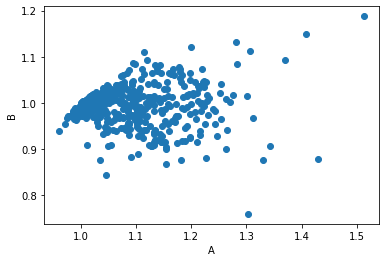

In [13]:
import matplotlib.pyplot as plt

plt.scatter(df_scal[0], df_scal[1])
plt.xlabel('A')
plt.ylabel('B')
plt.show()

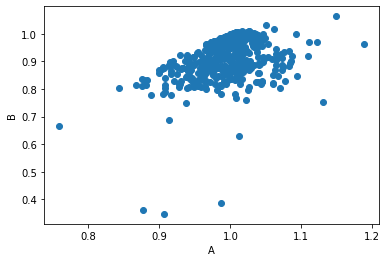

In [14]:
plt.scatter(df_scal[1], df_scal[2])
plt.xlabel('A')
plt.ylabel('B')
plt.show()

In [15]:
threshold = 2
z_scores = df_scal.apply(zscore)
abs_z_scores = np.abs(z_scores)
filtered_entries = (abs_z_scores > threshold).any(axis=1)
outliers = df_scal[filtered_entries]

In [16]:
outliers

,0,1,2
wt_M_82Z-10328,1.134733,0.920305,0.830305
wt_F_82Z-06658,1.219035,1.000616,0.897503
wt_F_82Z-07353,1.215512,0.931023,0.870882
wt_F_82Z-CF025,1.226717,0.880784,0.813809
wt_M_82Z-CF112,1.188505,0.916612,0.854615
...,...,...,...
wt_F_82Z-02979,1.430007,0.878044,0.831080
wt_F_82Z-CG330,1.214487,1.037481,0.934000
wt_F_82Z-CF270,1.265121,0.940729,0.905659
wt_F_82Z-09722,1.177599,1.077316,0.830343


In [17]:
z_scores

,0,1,2
wt_M_82Z-10911,-0.539109,0.155707,0.671564
wt_M_82Z-CF279,-0.834315,-0.304057,0.528397
wt_M_82Z-10328,0.961731,-2.072147,-1.547318
wt_F_82Z-06658,2.096683,0.142898,-0.585621
wt_F_82Z-08223,-0.051747,-0.451084,-1.431150
...,...,...,...
wt_M_82Z-07734,1.204939,-0.226596,-0.112769
wt_M_82Z-06778,-0.792384,-0.198449,0.615968
wt_F_82Z-09722,1.538833,2.258391,-1.546769
wt_M_82Z-CF991,0.732870,-0.726861,-0.718724


In [18]:
pd_males.sum(axis=1).describe()

count    355.000000
mean       2.988450
std        0.096209
min        2.560561
25%        2.946328
50%        2.988047
75%        3.024043
max        3.663657
dtype: float64

In [19]:
pd_females.sum(axis=1).describe()

count    423.000000
mean       3.004458
std        0.083676
min        2.568356
25%        2.964704
50%        3.002771
75%        3.040822
max        3.459966
dtype: float64

<AxesSubplot:>

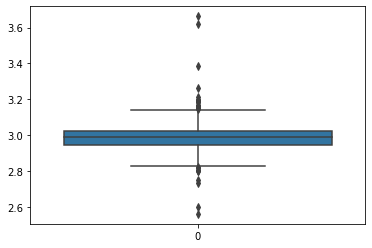

In [20]:
import seaborn as sns
sns.boxplot( data= pd_males.sum(axis=1))


<AxesSubplot:>

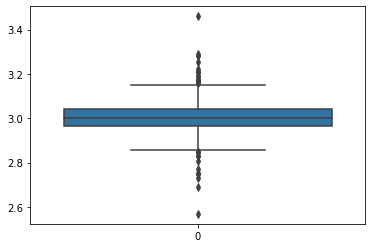

In [21]:
sns.boxplot( data= pd_females.sum(axis=1))

<AxesSubplot:>

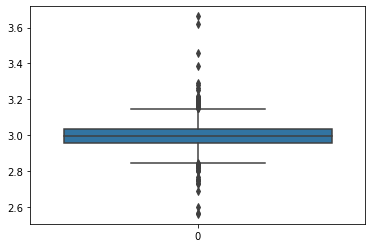

In [22]:
sns.boxplot( data= df_scal.sum(axis=1))

<AxesSubplot:ylabel='Count'>

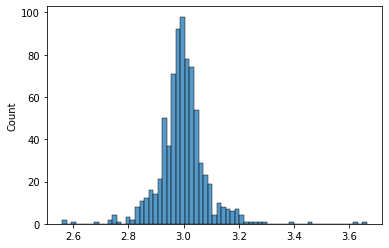

In [23]:
sns.histplot(df_scal.sum(axis=1))

<AxesSubplot:ylabel='Count'>

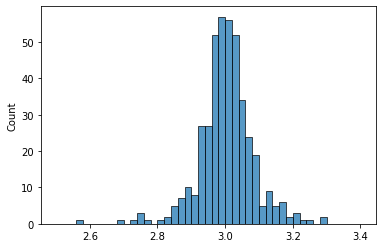

In [24]:
sns.histplot(pd_females.sum(axis=1),binrange=(2.5,3.4))

<AxesSubplot:ylabel='Count'>

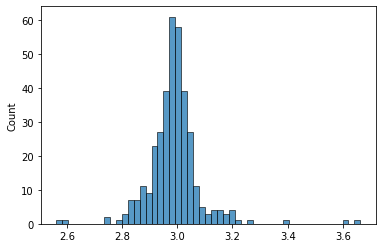

In [25]:
sns.histplot(pd_males.sum(axis=1))

<AxesSubplot:ylabel='Count'>

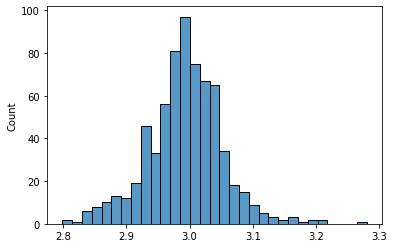

In [26]:
sns.histplot(df_scal[~filtered_entries].sum(axis=1))

In [27]:
threshold = 1.5
z_scores = df_scal.apply(zscore)
#z_scores = pd.DataFrame(df_scal.sum(axis=1)).apply(zscore)
abs_z_scores = np.abs(z_scores)
filtered_entries = (abs_z_scores > threshold).any(axis=1)
outliers = df_scal[filtered_entries]

In [28]:
outliers

,0,1,2
wt_M_82Z-10328,1.134733,0.920305,0.830305
wt_F_82Z-06658,1.219035,1.000616,0.897503
wt_F_82Z-07353,1.215512,0.931023,0.870882
wt_F_82Z-CF025,1.226717,0.880784,0.813809
wt_M_82Z-CF112,1.188505,0.916612,0.854615
...,...,...,...
wt_F_82Z-CF270,1.265121,0.940729,0.905659
wt_F_82Z-07609,1.176748,0.970448,0.913178
wt_M_82Z-11983,1.107932,0.990725,0.827026
wt_F_82Z-09722,1.177599,1.077316,0.830343


<AxesSubplot:>

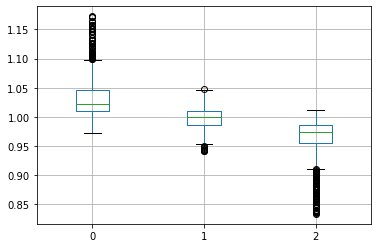

In [29]:
df_scal[~filtered_entries].boxplot()

In [30]:
list(df_scal[~filtered_entries].index)
import pathlib
res = pathlib.Path("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/images_4_average.txt")

In [31]:
res.write_text('\n'.join(list(df_scal[~filtered_entries].index)))

9089